PART A & B: Overfitting and regularization (polynomial regression)


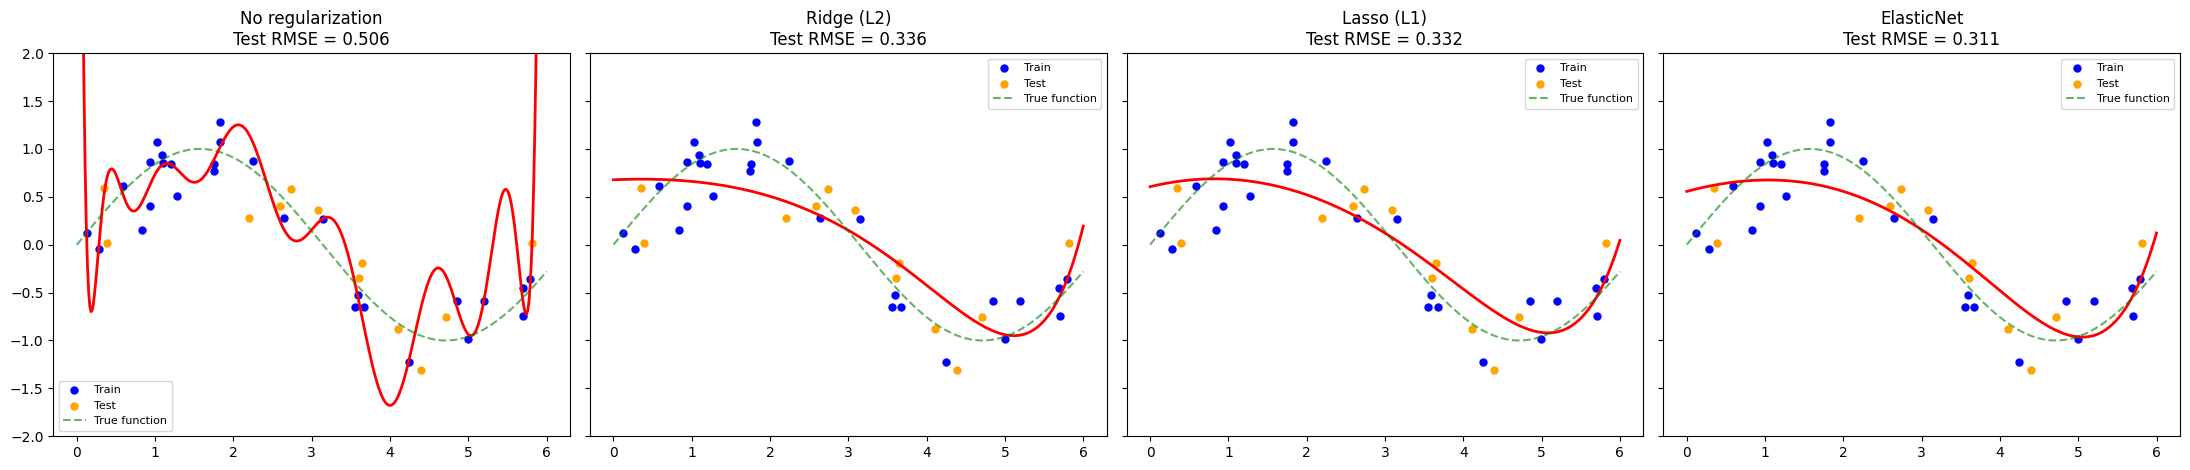

            Model  Train RMSE  Test RMSE  Gap (test - train)
No regularization      0.1544     0.5064              0.3521
       Ridge (L2)      0.3793     0.3356             -0.0437
       Lasso (L1)      0.3612     0.3323             -0.0289
       ElasticNet      0.3506     0.3114             -0.0392

A large gap between train and test error = overfitting.

PART C: Effect of regularization strength (alpha)


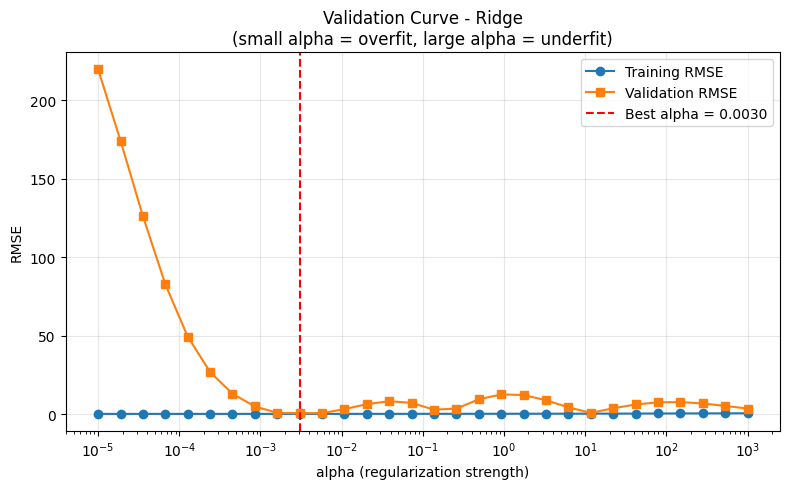


PART D: Coefficient shrinkage on the Diabetes dataset


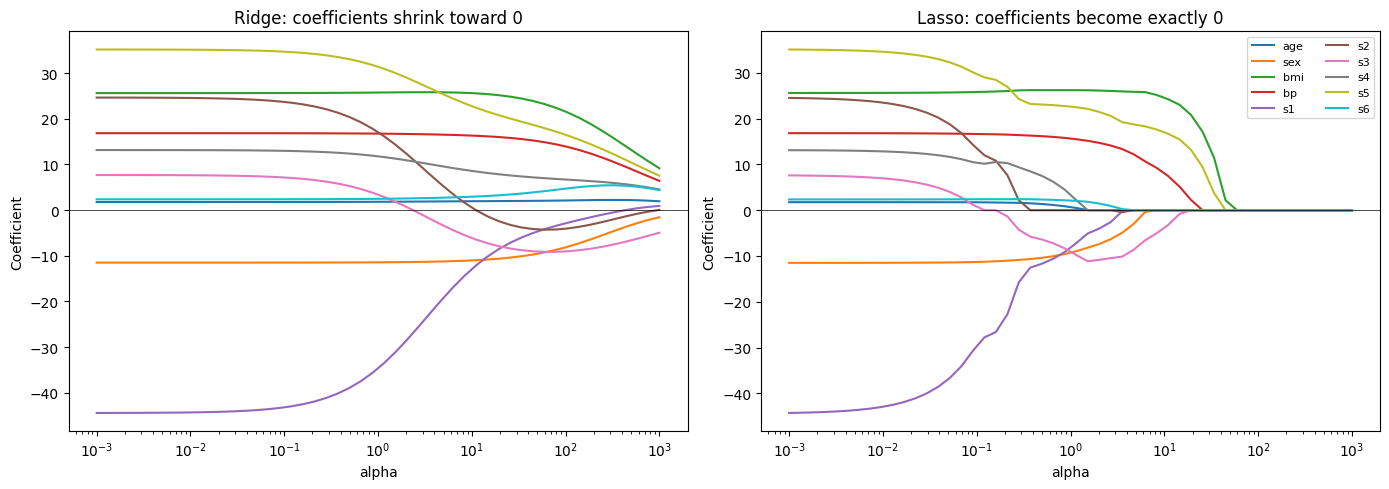

     Linear  Ridge (alpha=10)  Lasso (alpha=2)
age   1.754             1.931            0.000
sex -11.512           -11.028           -7.427
bmi  25.607            25.606           26.141
bp   16.829            16.304           14.736
s1  -44.449           -12.934           -4.066
s2   24.641             0.538           -0.000
s3    7.677            -6.125          -10.871
s4   13.139             8.569            0.000
s5   35.161            22.749           21.504
s6    2.351             2.918            1.467

Features removed by Lasso: ['age', 's2', 's4']

PART E: Automatic alpha selection with cross-validation
                 Model  Train R2  Test R2  Test RMSE
     Linear Regression    0.5279   0.4526     53.853
RidgeCV (alpha=44.984)    0.5205   0.4608     53.449
 LassoCV (alpha=1.655)    0.5190   0.4714     52.920

PART F: Regularization in Logistic Regression
        C  Train acc  Test acc  Non-zero features
   0.0001     0.3719    0.3743                  0
   0.0010     0.371

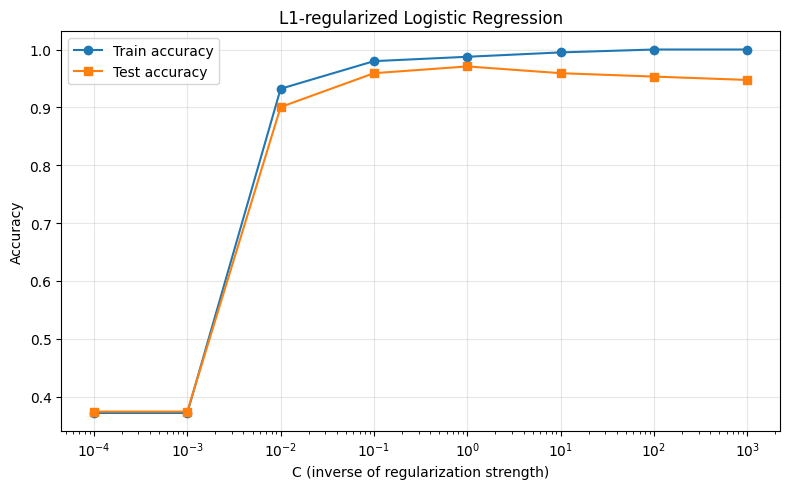


Conclusion: Regularization adds a penalty on large coefficients (Ridge: sum of squares, Lasso: sum of absolute values). It reduces model variance, shrinks the train/test gap and, with Lasso, removes useless features.


In [ ]:
"""
Assignment 8: Apply regularization to avoid overfitting.

Parts:
  A. Demonstrate overfitting with a high-degree polynomial (no regularization)
  B. Ridge (L2), Lasso (L1) and ElasticNet to fix it
  C. Effect of the regularization strength alpha (validation curve)
  D. Coefficient shrinkage paths + feature selection by Lasso
  E. Choosing alpha automatically with cross-validation (RidgeCV, LassoCV)
  F. Regularization in classification (Logistic Regression, C parameter)

Install: pip install numpy pandas matplotlib seaborn scikit-learn
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  RidgeCV, LassoCV, LogisticRegression)
from sklearn.model_selection import train_test_split, validation_curve
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

np.random.seed(42)

# ==================================================================
# PART A & B: Overfitting with polynomial regression, fixed by regularization
# ==================================================================
print("=" * 60)
print("PART A & B: Overfitting and regularization (polynomial regression)")
print("=" * 60)

# Small noisy dataset from a sine curve -> easy to overfit
X = np.sort(np.random.rand(40, 1) * 6, axis=0)
y = np.sin(X).ravel() + 0.3 * np.random.randn(40)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

DEGREE = 15   # far too flexible for 28 training points

models = {
    "No regularization": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=1.0),
    "Lasso (L1)": Lasso(alpha=0.01, max_iter=100000),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=100000),
}

X_line = np.linspace(0, 6, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8), sharey=True)
rows = []

for ax, (name, reg) in zip(axes, models.items()):
    pipe = make_pipeline(PolynomialFeatures(DEGREE, include_bias=False),
                         StandardScaler(), reg)
    pipe.fit(X_train, y_train)

    train_rmse = np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))
    test_rmse = np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
    rows.append({"Model": name,
                 "Train RMSE": round(train_rmse, 4),
                 "Test RMSE": round(test_rmse, 4),
                 "Gap (test - train)": round(test_rmse - train_rmse, 4)})

    ax.scatter(X_train, y_train, color="blue", s=25, label="Train")
    ax.scatter(X_test, y_test, color="orange", s=25, label="Test")
    ax.plot(X_line, pipe.predict(X_line), "r", linewidth=2)
    ax.plot(X_line, np.sin(X_line), "g--", alpha=0.6, label="True function")
    ax.set_ylim(-2, 2)
    ax.set_title(f"{name}\nTest RMSE = {test_rmse:.3f}")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(pd.DataFrame(rows).to_string(index=False))
print("\nA large gap between train and test error = overfitting.")

# ==================================================================
# PART C: Effect of alpha (validation curve)
# ==================================================================
print("\n" + "=" * 60)
print("PART C: Effect of regularization strength (alpha)")
print("=" * 60)

alphas = np.logspace(-5, 3, 30)
pipe = make_pipeline(PolynomialFeatures(DEGREE, include_bias=False),
                     StandardScaler(), Ridge())
train_scores, val_scores = validation_curve(
    pipe, X, y, param_name="ridge__alpha", param_range=alphas,
    cv=5, scoring="neg_mean_squared_error")

train_rmse = np.sqrt(-train_scores.mean(axis=1))
val_rmse = np.sqrt(-val_scores.mean(axis=1))

plt.figure(figsize=(8, 5))
plt.semilogx(alphas, train_rmse, "o-", label="Training RMSE")
plt.semilogx(alphas, val_rmse, "s-", label="Validation RMSE")
plt.axvline(alphas[np.argmin(val_rmse)], color="red", linestyle="--",
            label=f"Best alpha = {alphas[np.argmin(val_rmse)]:.4f}")
plt.xlabel("alpha (regularization strength)")
plt.ylabel("RMSE")
plt.title("Validation Curve - Ridge\n(small alpha = overfit, large alpha = underfit)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==================================================================
# PART D: Coefficient shrinkage and Lasso feature selection (Diabetes)
# ==================================================================
print("\n" + "=" * 60)
print("PART D: Coefficient shrinkage on the Diabetes dataset")
print("=" * 60)

data = load_diabetes(as_frame=True)
Xd, yd = data.data, data.target
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(Xd_train)
Xd_train_s = scaler.transform(Xd_train)
Xd_test_s = scaler.transform(Xd_test)

alpha_range = np.logspace(-3, 3, 50)
ridge_coefs, lasso_coefs = [], []
for a in alpha_range:
    ridge_coefs.append(Ridge(alpha=a).fit(Xd_train_s, yd_train).coef_)
    lasso_coefs.append(Lasso(alpha=a, max_iter=100000).fit(Xd_train_s, yd_train).coef_)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, name in enumerate(Xd.columns):
    ax[0].semilogx(alpha_range, np.array(ridge_coefs)[:, i], label=name)
    ax[1].semilogx(alpha_range, np.array(lasso_coefs)[:, i], label=name)
ax[0].set_title("Ridge: coefficients shrink toward 0")
ax[1].set_title("Lasso: coefficients become exactly 0")
for a in ax:
    a.set_xlabel("alpha")
    a.set_ylabel("Coefficient")
    a.axhline(0, color="black", linewidth=0.5)
ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

lin = LinearRegression().fit(Xd_train_s, yd_train)
lasso = Lasso(alpha=2.0, max_iter=100000).fit(Xd_train_s, yd_train)
coef_table = pd.DataFrame({
    "Linear": lin.coef_,
    "Ridge (alpha=10)": Ridge(alpha=10).fit(Xd_train_s, yd_train).coef_,
    "Lasso (alpha=2)": lasso.coef_,
}, index=Xd.columns).round(3)
print(coef_table)
print("\nFeatures removed by Lasso:", list(Xd.columns[lasso.coef_ == 0]))

# ==================================================================
# PART E: Choose alpha automatically using cross-validation
# ==================================================================
print("\n" + "=" * 60)
print("PART E: Automatic alpha selection with cross-validation")
print("=" * 60)

ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(Xd_train_s, yd_train)
lasso_cv = LassoCV(alphas=None, cv=5, max_iter=100000, random_state=0).fit(Xd_train_s, yd_train)

results = []
for name, model in [("Linear Regression", lin),
                    (f"RidgeCV (alpha={ridge_cv.alpha_:.3f})", ridge_cv),
                    (f"LassoCV (alpha={lasso_cv.alpha_:.3f})", lasso_cv)]:
    results.append({
        "Model": name,
        "Train R2": round(r2_score(yd_train, model.predict(Xd_train_s)), 4),
        "Test R2": round(r2_score(yd_test, model.predict(Xd_test_s)), 4),
        "Test RMSE": round(np.sqrt(mean_squared_error(yd_test, model.predict(Xd_test_s))), 3),
    })
print(pd.DataFrame(results).to_string(index=False))

# ==================================================================
# PART F: Regularization in classification (Logistic Regression)
#         sklearn uses C = 1/lambda  ->  small C = strong regularization
# ==================================================================
print("\n" + "=" * 60)
print("PART F: Regularization in Logistic Regression")
print("=" * 60)

cancer = load_breast_cancer(as_frame=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.3, random_state=42, stratify=cancer.target)
sc = StandardScaler().fit(Xc_train)
Xc_train_s, Xc_test_s = sc.transform(Xc_train), sc.transform(Xc_test)

C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
tr_acc, te_acc, nonzero = [], [], []
for C in C_values:
    clf = LogisticRegression(penalty="l1", solver="liblinear", C=C).fit(Xc_train_s, yc_train)
    tr_acc.append(clf.score(Xc_train_s, yc_train))
    te_acc.append(clf.score(Xc_test_s, yc_test))
    nonzero.append(np.sum(clf.coef_ != 0))

print(pd.DataFrame({"C": C_values, "Train acc": np.round(tr_acc, 4),
                    "Test acc": np.round(te_acc, 4),
                    "Non-zero features": nonzero}).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.semilogx(C_values, tr_acc, "o-", label="Train accuracy")
plt.semilogx(C_values, te_acc, "s-", label="Test accuracy")
plt.xlabel("C (inverse of regularization strength)")
plt.ylabel("Accuracy")
plt.title("L1-regularized Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nConclusion: Regularization adds a penalty on large coefficients "
      "(Ridge: sum of squares, Lasso: sum of absolute values). It reduces model "
      "variance, shrinks the train/test gap and, with Lasso, removes useless features.")